# Extending the training data for diversity: UTKFace + FairFace

UTKFace is 42% White and has no Middle Eastern category. [FairFace](https://github.com/joojs/fairface)
(CC BY 4.0) adds ~97k faces balanced across 7 groups, including **Middle Eastern** and **Latino**, but labels age
as ranges (20-29, 30-39, …) instead of exact years.

This notebook fine-tunes the EfficientNetB0 from `gradute_preoject.ipynb` on both datasets with an **interval loss**:
a prediction inside the labelled range costs nothing; outside it, the distance to the range is penalised (Huber).
For UTKFace's exact ages the range is a single year, so the loss is the same as before.

Before → after is measured per group on two test sets the model never sees during training:
the same UTKFace test split as the main notebook, and FairFace's official validation split.
FairFace faces are cropped by `tools/prepare_fairface.py` with the web app's own preprocessing, so their
framing matches UTKFace.

In [1]:
import csv
import json
import os

import cv2
import keras
import matplotlib.pyplot as plt
import numpy as np
import tensorflow as tf
from sklearn.model_selection import train_test_split
from tensorflow.keras import callbacks, optimizers

SEED = 42
IMG_SIZE = 128
MAX_AGE = 90
BATCH_SIZE = 32
AUTOTUNE = tf.data.AUTOTUNE
UTKFACE_DIR = os.environ.get("UTKFACE_DIR", "UTKFace")
FAIRFACE_DIR = os.environ.get("FAIRFACE_DIR", "fairface_prepared")   # output of tools/prepare_fairface.py
BASE_MODEL = os.environ.get("BASE_MODEL", "age_efficientnet.keras")   # trained by gradute_preoject.ipynb

tf.keras.utils.set_random_seed(SEED)
print("GPU:", tf.config.list_physical_devices("GPU"))

I0000 00:00:1792242711.895640    3312 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


I0000 00:00:1792242714.554858    3312 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


## 1. Data

In [2]:
# UTKFace: same filtering, order and split as gradute_preoject.ipynb, so the test set is identical
UTK_RACES = {"0": "White", "1": "Black", "2": "Asian", "3": "Indian", "4": "Others"}
utk_images, utk_ages, utk_races = [], [], []
for filename in sorted(os.listdir(UTKFACE_DIR)):
    if filename.endswith(".jpg"):
        try:
            parts = filename.split("_")
            age = int(parts[0])
            if 0 <= age <= MAX_AGE:
                img = cv2.resize(cv2.imread(os.path.join(UTKFACE_DIR, filename)), (IMG_SIZE, IMG_SIZE))
                utk_images.append(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
                utk_ages.append(age)
                utk_races.append(UTK_RACES.get(parts[2], "Unlabelled") if len(parts) >= 4 else "Unlabelled")
        except Exception as e:
            print(f"Skipping {filename}: {e}")

utk_images = np.array(utk_images, dtype=np.uint8)
utk_ages = np.array(utk_ages, dtype=np.float32)
utk_races = np.array(utk_races)

idx = np.arange(len(utk_ages))
utk_train, utk_test = train_test_split(idx, test_size=0.2, random_state=SEED)
utk_train, utk_val = train_test_split(utk_train, test_size=0.1, random_state=SEED)
print(f"UTKFace  train {len(utk_train)} | val {len(utk_val)} | test {len(utk_test)}")

UTKFace  train 17006 | val 1890 | test 4725


FairFace train 77846 | val 8650 | test 10925


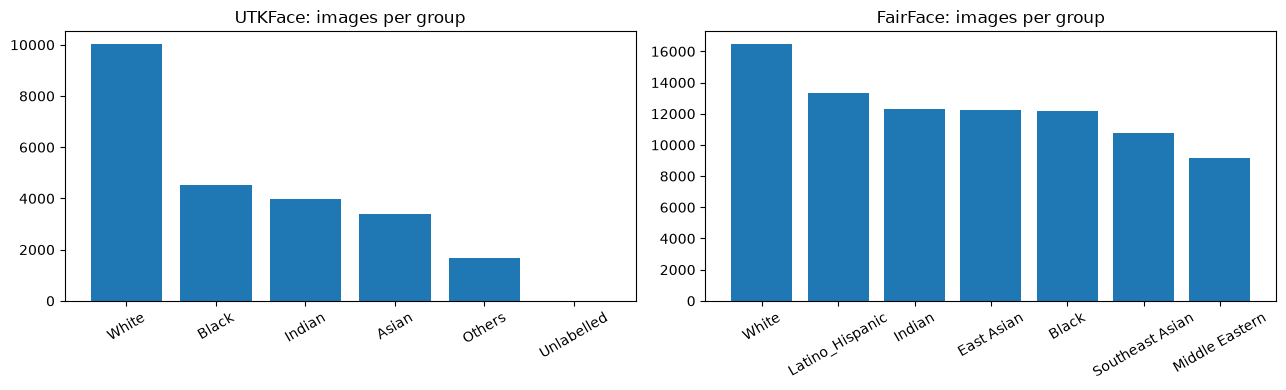

In [3]:
def load_fairface(split):
    images = np.load(os.path.join(FAIRFACE_DIR, f"{split}_images.npy"), mmap_mode="r")
    with open(os.path.join(FAIRFACE_DIR, f"{split}_labels.csv"), encoding="utf-8") as f:
        rows = list(csv.DictReader(f))
    lo = np.array([float(r["age_lo"]) for r in rows], np.float32)
    hi = np.array([float(r["age_hi"]) for r in rows], np.float32)
    races = np.array([r["race"] for r in rows])
    bins = np.array([r["age_bin"] for r in rows])
    return images, lo, hi, races, bins

ff_images, ff_lo, ff_hi, ff_races, ff_bins = load_fairface("train")
# FairFace's official validation split is never trained on: it is our second test set
ff_test_images, ff_test_lo, ff_test_hi, ff_test_races, ff_test_bins = load_fairface("val")
ff_test_images = np.asarray(ff_test_images)

ff_idx = np.arange(len(ff_lo))
ff_train, ff_val = train_test_split(ff_idx, test_size=0.1, random_state=SEED, stratify=ff_races)
print(f"FairFace train {len(ff_train)} | val {len(ff_val)} | test {len(ff_test_lo)}")

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for ax, (title, races) in zip(axes, [("UTKFace", utk_races), ("FairFace", ff_races)]):
    names, counts = np.unique(races, return_counts=True)
    order = np.argsort(-counts)
    ax.bar(names[order], counts[order])
    ax.set_title(f"{title}: images per group")
    ax.tick_params(axis="x", rotation=30)
plt.tight_layout()
plt.show()

## 2. Interval loss and data pipeline

In [4]:
def distance_to_interval(y_true, y_pred):
    """0 inside [lo, hi]; otherwise the distance to the nearest end (normalized ages)."""
    lo, hi = y_true[:, 0:1], y_true[:, 1:2]
    return tf.nn.relu(lo - y_pred) + tf.nn.relu(y_pred - hi)

def interval_huber(y_true, y_pred, delta=0.1):
    d = distance_to_interval(y_true, y_pred)
    return tf.reduce_mean(tf.where(d <= delta, 0.5 * d ** 2, delta * (d - 0.5 * delta)))

def interval_mae(y_true, y_pred):
    """Years outside the labelled range (= ordinary MAE for exact ages)."""
    return tf.reduce_mean(distance_to_interval(y_true, y_pred)) * MAX_AGE

utk_intervals = np.stack([utk_ages, utk_ages], 1) / MAX_AGE
ff_intervals = np.stack([ff_lo, ff_hi], 1) / MAX_AGE

def train_batches():
    """Shuffled batches drawn from UTKFace (in memory) and FairFace (memory-mapped from disk)."""
    source = np.r_[np.zeros(len(utk_train), np.int8), np.ones(len(ff_train), np.int8)]
    index = np.r_[utk_train, ff_train]
    order = np.random.permutation(len(index))
    for start in range(0, len(order), BATCH_SIZE):
        sel = order[start:start + BATCH_SIZE]
        u = np.sort(index[sel][source[sel] == 0])
        f = np.sort(index[sel][source[sel] == 1])
        yield (np.concatenate([utk_images[u], ff_images[f]]),
               np.concatenate([utk_intervals[u], ff_intervals[f]]).astype(np.float32))

train_ds = tf.data.Dataset.from_generator(
    train_batches,
    output_signature=(tf.TensorSpec((None, IMG_SIZE, IMG_SIZE, 3), tf.uint8), tf.TensorSpec((None, 2), tf.float32)),
).repeat().map(lambda x, y: (tf.cast(x, tf.float32), y), num_parallel_calls=AUTOTUNE).prefetch(4)
# The generator reshuffles on every pass; repeat() + steps_per_epoch gives Keras a fixed epoch length
STEPS_PER_EPOCH = int(np.ceil((len(utk_train) + len(ff_train)) / BATCH_SIZE))

val_images = np.concatenate([utk_images[utk_val], np.asarray(ff_images[np.sort(ff_val)])])
val_intervals = np.concatenate([utk_intervals[utk_val], ff_intervals[np.sort(ff_val)]]).astype(np.float32)
val_ds = tf.data.Dataset.from_tensor_slices((val_images, val_intervals)).batch(64) \
    .map(lambda x, y: (tf.cast(x, tf.float32), y), num_parallel_calls=AUTOTUNE).prefetch(AUTOTUNE)

## 3. Fine-tune EfficientNetB0 on both datasets

Starting from the model trained on UTKFace only (4.97 years test MAE) instead of ImageNet: it already knows
age, so a few epochs with a small learning rate adapt it to the new faces.

Resuming: 11 epochs logged, best val_interval_mae 2.6982462406158447


/root/age/.venv/lib/python3.12/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


Epoch 12/15


E0000 00:00:1792242771.870785    3312 meta_optimizer.cc:967] layout failed: INVALID_ARGUMENT: Size of values 0 does not match size of permutation 4 @ fanin shape inStatefulPartitionedCall/functional_5_1/efficientnetb0_1/block2b_drop_1/stateless_dropout/SelectV2-2-TransposeNHWCToNCHW-LayoutOptimizer


2965/2965 - 639s - 215ms/step - interval_mae: 2.2046 - loss: 8.9235e-04 - val_interval_mae: 2.7315 - val_loss: 0.0013 - learning_rate: 2.5000e-05


...

2965/2965 - 600s - 202ms/step - interval_mae: 2.1282 - loss: 8.3614e-04 - val_interval_mae: 2.7417 - val_loss: 0.0013 - learning_rate: 2.5000e-05


Epoch 14/15


2965/2965 - 609s - 205ms/step - interval_mae: 2.0773 - loss: 8.0137e-04 - val_interval_mae: 2.7493 - val_loss: 0.0013 - learning_rate: 2.5000e-05


Epoch 15/15


2965/2965 - 602s - 203ms/step - interval_mae: 1.9753 - loss: 7.3718e-04 - val_interval_mae: 2.7174 - val_loss: 0.0013 - learning_rate: 1.2500e-05


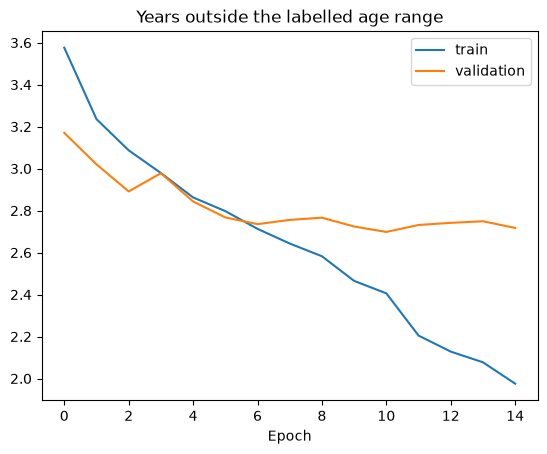

In [5]:
# Long runs on a laptop GPU can be interrupted, so training is resumable: BackupAndRestore saves the model,
# optimizer and epoch after every epoch, and re-running this cell continues from there. The best weights
# so far are kept separately, and the CSV log keeps the full history across restarts.
BACKUP_DIR = "diverse_training_backup"
CSV_LOG = "diverse_training_log.csv"
BEST_WEIGHTS = "age_efficientnet_diverse_best.weights.h5"

best_so_far = None
if os.path.exists(CSV_LOG):
    with open(CSV_LOG, encoding="utf-8") as f:
        logged = [float(r["val_interval_mae"]) for r in csv.DictReader(f)]
    best_so_far = min(logged) if logged else None
    print(f"Resuming: {len(logged)} epochs logged, best val_interval_mae {best_so_far}")

model = keras.saving.load_model(BASE_MODEL, compile=False)
model.compile(optimizer=optimizers.Adam(5e-5), loss=interval_huber, metrics=[interval_mae])

model.fit(
    train_ds,
    validation_data=val_ds,
    steps_per_epoch=STEPS_PER_EPOCH,
    epochs=15,
    callbacks=[
        callbacks.BackupAndRestore(BACKUP_DIR),
        callbacks.CSVLogger(CSV_LOG, append=True),
        callbacks.ModelCheckpoint(BEST_WEIGHTS, monitor="val_interval_mae", mode="min", save_best_only=True,
                                  save_weights_only=True, initial_value_threshold=best_so_far),
        callbacks.EarlyStopping(monitor="val_interval_mae", mode="min", patience=4),
        callbacks.ReduceLROnPlateau(monitor="val_interval_mae", mode="min", factor=0.5, patience=2, min_lr=1e-6),
    ],
    verbose=2,
)
model.load_weights(BEST_WEIGHTS)
model.save("age_efficientnet_diverse.keras")

with open(CSV_LOG, encoding="utf-8") as f:
    log = list(csv.DictReader(f))
plt.plot([float(r["interval_mae"]) for r in log], label="train")
plt.plot([float(r["val_interval_mae"]) for r in log], label="validation")
plt.title("Years outside the labelled age range")
plt.xlabel("Epoch")
plt.legend()
plt.show()

## 4. Before → after, per group

In [6]:
def predict_years(m, images):
    return m.predict(np.asarray(images, np.float32), batch_size=64, verbose=0).ravel() * MAX_AGE

before = keras.saving.load_model(BASE_MODEL, compile=False)
after = model

# UTKFace test (exact ages)
utk_true = utk_ages[utk_test]
utk_group = utk_races[utk_test]
utk_err = {name: np.abs(predict_years(m, utk_images[utk_test]) - utk_true) for name, m in [("before", before), ("after", after)]}

# FairFace test (age ranges): years outside the range, and % of predictions inside the range
ff_pred = {name: predict_years(m, ff_test_images) for name, m in [("before", before), ("after", after)]}
ff_out = {k: np.maximum(ff_test_lo - p, 0) + np.maximum(p - ff_test_hi, 0) for k, p in ff_pred.items()}

results = {"utkface_test": {}, "fairface_test": {}}
print(f"UTKFace test — MAE in years ({len(utk_true)} faces)")
print(f"{'group':<16}{'faces':>7}{'before':>9}{'after':>8}")
for g in ["All"] + sorted(set(utk_group) - {"Unlabelled"}):
    mask = np.ones(len(utk_true), bool) if g == "All" else utk_group == g
    b, a = utk_err["before"][mask].mean(), utk_err["after"][mask].mean()
    results["utkface_test"][g] = {"faces": int(mask.sum()), "mae_before": round(float(b), 2), "mae_after": round(float(a), 2)}
    print(f"{g:<16}{mask.sum():>7}{b:>9.2f}{a:>8.2f}")

print(f"\nFairFace test — years outside the labelled range / % inside the range ({len(ff_test_lo)} faces)")
print(f"{'group':<16}{'faces':>7}{'before':>9}{'after':>8}{'in-range before':>17}{'after':>8}")
for g in ["All"] + sorted(set(ff_test_races)):
    mask = np.ones(len(ff_test_lo), bool) if g == "All" else ff_test_races == g
    b, a = ff_out["before"][mask].mean(), ff_out["after"][mask].mean()
    ib, ia = (ff_out["before"][mask] == 0).mean() * 100, (ff_out["after"][mask] == 0).mean() * 100
    results["fairface_test"][g] = {"faces": int(mask.sum()), "outside_before": round(float(b), 2), "outside_after": round(float(a), 2),
                                   "in_range_before": round(float(ib), 1), "in_range_after": round(float(ia), 1)}
    print(f"{g:<16}{mask.sum():>7}{b:>9.2f}{a:>8.2f}{ib:>16.1f}%{ia:>7.1f}%")

UTKFace test — MAE in years (4725 faces)
group             faces   before   after
All                4725     4.97    4.83
Asian               680     3.45    3.37
Black               881     5.35    5.21
Indian              835     4.91    4.69
Others              335     3.84    3.75
White              1994     5.53    5.41

FairFace test — years outside the labelled range / % inside the range (10925 faces)
group             faces   before   after  in-range before   after
All               10925     4.55    2.32            37.6%   47.8%
Black              1551     5.20    2.68            35.1%   43.8%
East Asian         1542     3.94    2.03            41.1%   53.2%
Indian             1512     4.33    2.20            36.0%   48.7%
Latino_Hispanic    1622     4.49    2.40            38.6%   45.7%
Middle Eastern     1208     4.26    2.21            38.9%   47.8%
Southeast Asian    1414     4.43    2.26            39.6%   49.6%
White              2076     4.98    2.40            35.5%  

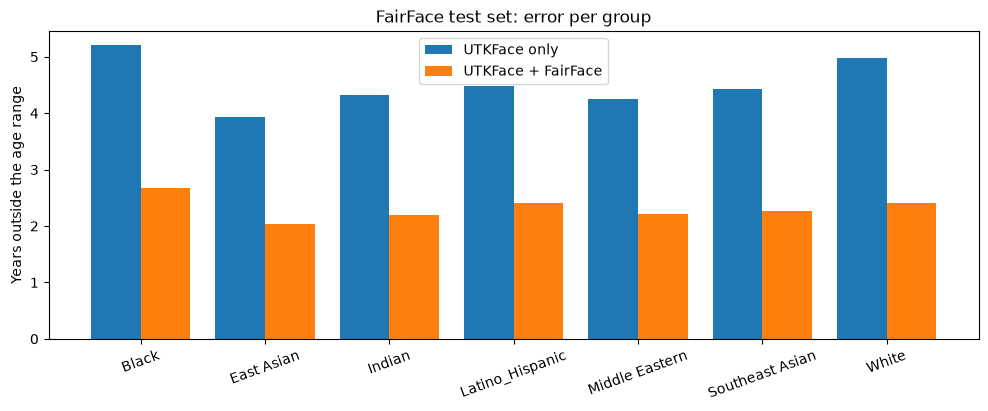

Wrote models/metrics_diverse.json


In [7]:
groups = [g for g in results["fairface_test"] if g != "All"]
x = np.arange(len(groups))
plt.figure(figsize=(12, 4))
plt.bar(x - 0.2, [results["fairface_test"][g]["outside_before"] for g in groups], 0.4, label="UTKFace only")
plt.bar(x + 0.2, [results["fairface_test"][g]["outside_after"] for g in groups], 0.4, label="UTKFace + FairFace")
plt.xticks(x, groups, rotation=20)
plt.ylabel("Years outside the age range")
plt.title("FairFace test set: error per group")
plt.legend()
plt.show()

os.makedirs("models", exist_ok=True)
with open(os.path.join("models", "metrics_diverse.json"), "w", encoding="utf-8") as f:
    json.dump(results, f, ensure_ascii=False, indent=2)
print("Wrote models/metrics_diverse.json")